In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import seaborn as sns


In [3]:
DF = pd.read_csv(r"C:\Users\NAINA\OneDrive\Documents\GitHub\Data_Analysis_Internship_Projects\Customer_retension_Project\DATA\European_Bank.csv")
print("dataset loaded successfully")

dataset loaded successfully


In [4]:
DF.head()


,Year,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,2025,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2025,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,2025,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,2025,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,2025,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
DF.shape

(10000, 14)

In [6]:
DF.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Year             10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [7]:
DF.isnull().sum()

Year               0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [8]:
print(DF['Exited'].unique())
print(DF['HasCrCard'].unique())
print(DF['IsActiveMember'].unique())

[1 0]
[1 0]
[1 0]


In [9]:
DF.drop(['CustomerId', 'Surname', 'Year'], axis=1, inplace=True)
print("Columns dropped successfully!")
print(DF.shape)

Columns dropped successfully!
(10000, 11)


In [10]:
DF. columns


Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
       'Exited'],
      dtype='object')

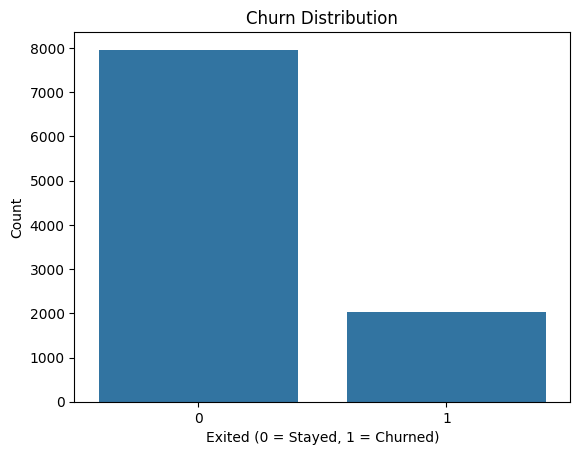

In [11]:
#Churn Distribution
sns.countplot(x="Exited", data=DF)
plt.title("Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Churned)")
plt.ylabel("Count")
plt.show()


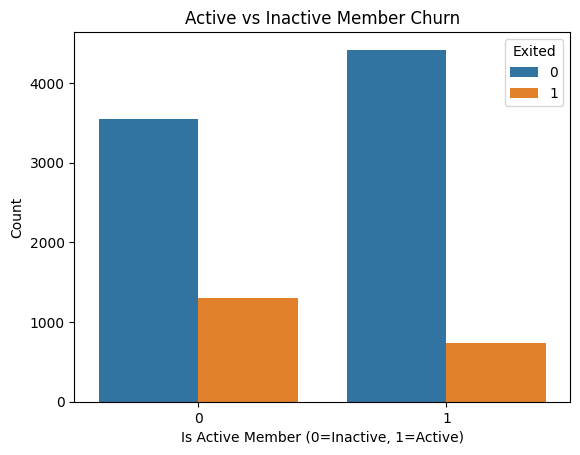

In [12]:
# Engagement vs Churn
sns.countplot(x='IsActiveMember', hue='Exited', data=DF)
plt.title('Active vs Inactive Member Churn')
plt.xlabel('Is Active Member (0=Inactive, 1=Active)')
plt.ylabel('Count')
plt.show()

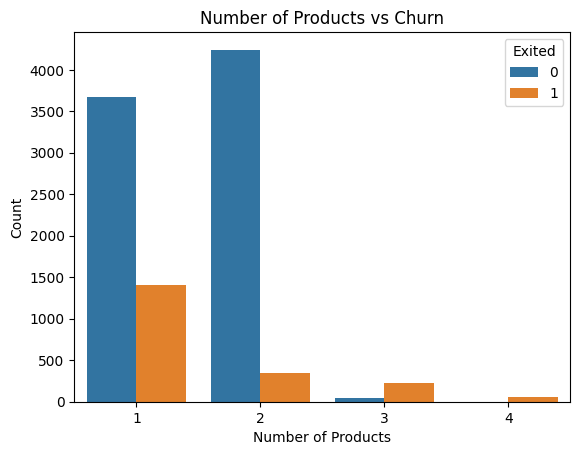

In [13]:
# Products vs Churn
sns.countplot(x='NumOfProducts', hue='Exited', data=DF)
plt.title('Number of Products vs Churn')
plt.xlabel('Number of Products')
plt.ylabel('Count')
plt.show()

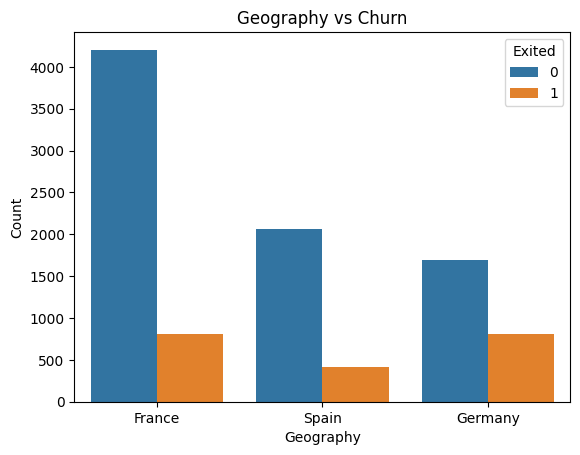

In [14]:
# Geography vs Churn
sns.countplot(x='Geography', hue='Exited', data=DF)
plt.title('Geography vs Churn')
plt.xlabel('Geography')
plt.ylabel('Count')
plt.show()

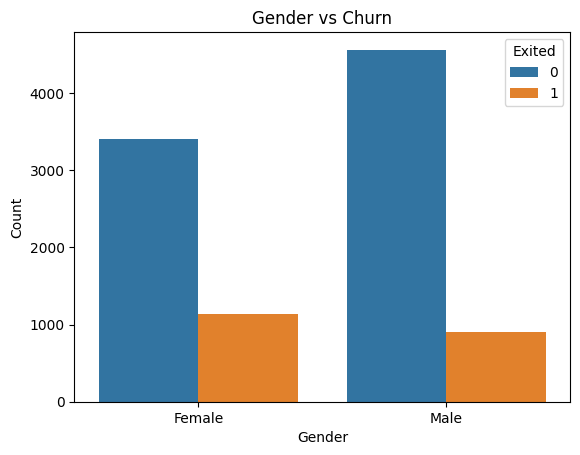

In [15]:
#Gender vs Churn
sns.countplot(x='Gender', hue='Exited', data=DF)
plt.title('Gender vs Churn')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

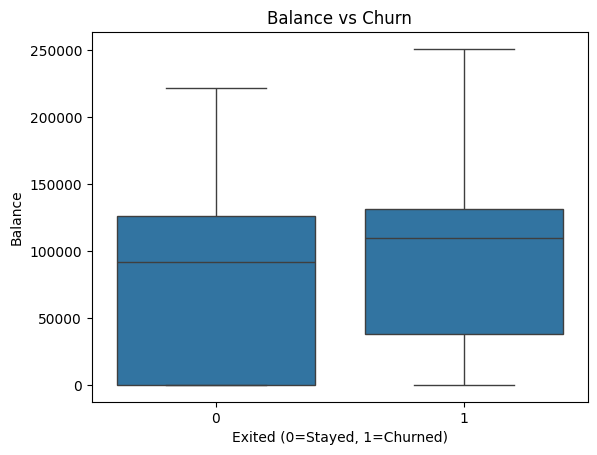

In [16]:
# Balance vs Churn
sns.boxplot(x='Exited', y='Balance', data=DF)
plt.title('Balance vs Churn')
plt.xlabel('Exited (0=Stayed, 1=Churned)')
plt.ylabel('Balance')
plt.show()

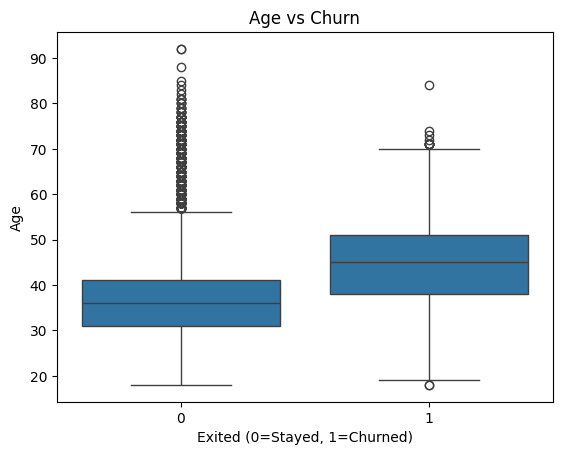

In [17]:
#Age vs Churn
sns.boxplot(x='Exited', y='Age', data=DF)
plt.title('Age vs Churn')
plt.xlabel('Exited (0=Stayed, 1=Churned)')
plt.ylabel('Age')
plt.show()

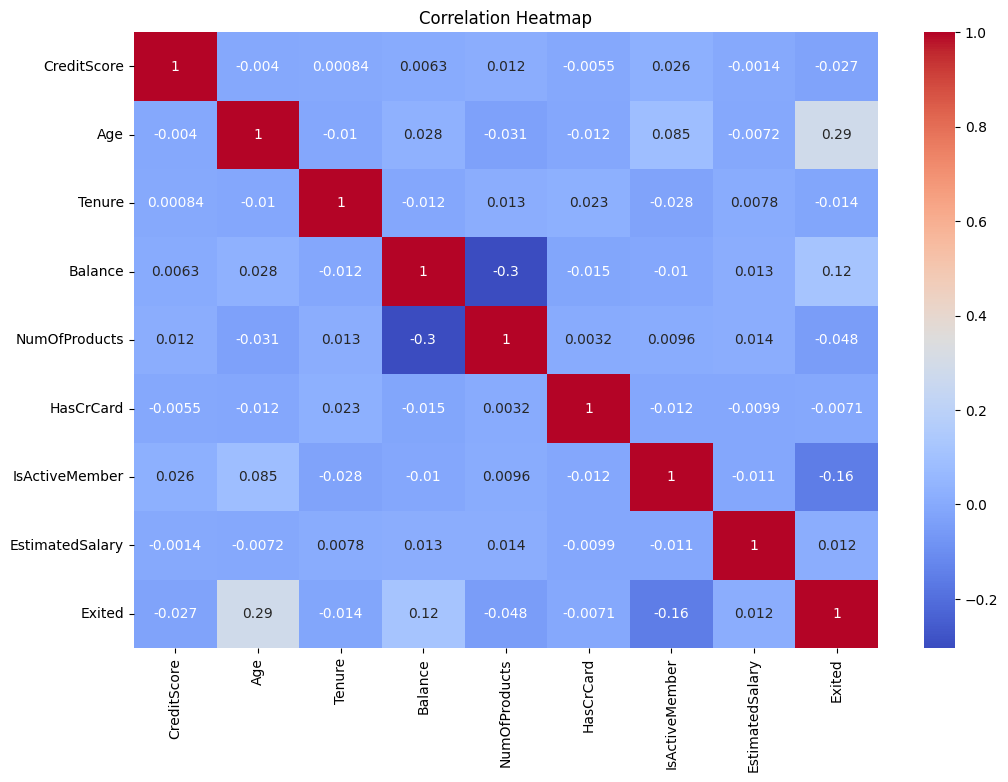

In [18]:
#Correlation Heatmap
plt.figure(figsize=(12,8))
sns.heatmap(DF.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

In [19]:
# Feature Engineering
# Create Engagement Profile
def Engagement_Profile(row):
    if row['IsActiveMember'] == 1 and row['NumOfProducts'] >= 2:
        return 'Highly Engaged'
    elif row['IsActiveMember'] == 0 and row['Balance'] > 100000:
        return 'High Value Disengaged'
    elif row['IsActiveMember'] == 1 and row['NumofProducts'] == 1:
        return 'Active Low Product'
    else:
        return 'inactive Low Engagement'

In [21]:
#Create Relationship Score
DF['RelationshipScore'] = (
    DF['IsActiveMember'] * 40 +
    DF['NumOfProducts'] * 20 +
    DF['HasCrCard'] * 10
)
print(DF['RelationshipScore'].value_counts())

RelationshipScore
70     1887
30     1803
90     1757
50     1511
60      829
80      720
20      718
40      633
110      78
100      35
130      19
120      10
Name: count, dtype: int64


In [22]:
# Create Premium At Risk Flag
DF['PremiumAtRisk'] = (
    (DF['Balance'] > 100000) & 
    (DF['IsActiveMember'] == 0)
).astype(int)

print(DF['PremiumAtRisk'].value_counts())

PremiumAtRisk
0    7644
1    2356
Name: count, dtype: int64


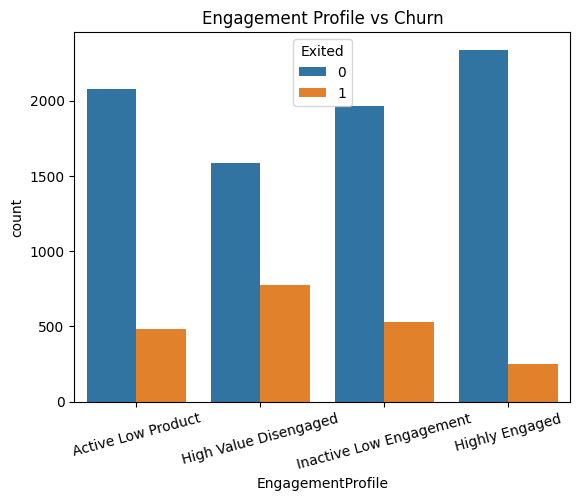

In [28]:
#Visualise Engagement Profile vs Churn
sns.countplot(x='EngagementProfile', hue='Exited', data=DF)
plt.title('Engagement Profile vs Churn')
plt.xticks(rotation=15)
plt.show()

In [27]:
def engagement_profile(row):
    if row['IsActiveMember'] == 1 and row['NumOfProducts'] >= 2:
        return 'Highly Engaged'
    elif row['IsActiveMember'] == 0 and row['Balance'] > 100000:
        return 'High Value Disengaged'
    elif row['IsActiveMember'] == 1 and row['NumOfProducts'] == 1:
        return 'Active Low Product'
    else:
        return 'Inactive Low Engagement'

DF['EngagementProfile'] = DF.apply(engagement_profile, axis=1)
print("Done!")
print(DF['EngagementProfile'].value_counts())

Done!
EngagementProfile
Highly Engaged             2588
Active Low Product         2563
Inactive Low Engagement    2493
High Value Disengaged      2356
Name: count, dtype: int64


In [29]:
# KPI 1: Engagement Retention Ratio
active_churn = DF[DF['IsActiveMember']==1]['Exited'].mean()
inactive_churn = DF[DF['IsActiveMember']==0]['Exited'].mean()

print(f"Active Member Churn Rate: {active_churn*100:.2f}%")
print(f"Inactive Member Churn Rate: {inactive_churn*100:.2f}%")
print(f"Inactive members are {inactive_churn/active_churn:.2f}x more likely to churn")

Active Member Churn Rate: 14.27%
Inactive Member Churn Rate: 26.85%
Inactive members are 1.88x more likely to churn


In [30]:
# KPI 2: Product Depth Index
product_churn = DF.groupby('NumOfProducts')['Exited'].mean()*100
print("Churn Rate by Number of Products:")
print(product_churn.round(2))

Churn Rate by Number of Products:
NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00
Name: Exited, dtype: float64


In [31]:
# KPI 3: High Balance Disengagement Rate
high_balance = DF[DF['Balance'] > 100000]
rate = high_balance[high_balance['IsActiveMember']==0]['Exited'].mean()
print(f"High Balance Disengagement Churn Rate: {rate*100:.2f}%")

High Balance Disengagement Churn Rate: 32.77%


In [32]:
# KPI 4: Credit Card Stickiness
card_churn = DF.groupby('HasCrCard')['Exited'].mean()*100
print("Churn Rate by Credit Card Ownership:")
print(card_churn.round(2))

Churn Rate by Credit Card Ownership:
HasCrCard
0    20.81
1    20.18
Name: Exited, dtype: float64


In [33]:
#KPI 5: Relationship Strength Index
relationship = DF.groupby('RelationshipScore')['Exited'].mean()*100
print("Churn Rate by Relationship Score:")
print(relationship.round(2))

Churn Rate by Relationship Score:
RelationshipScore
20      34.54
30      37.49
40      10.43
50       9.66
60      24.97
70      21.89
80       7.64
90       6.37
100     77.14
110     74.36
120    100.00
130    100.00
Name: Exited, dtype: float64


In [34]:
# Premium At Risk Summary
premium_risk = DF[
    (DF['Balance'] > 100000) &
    (DF['IsActiveMember'] == 0) &
    (DF['Exited'] == 1)
]
print(f"Total Premium At Risk Customers who churned: {len(premium_risk)}")
print(premium_risk[['Age', 'Balance', 'NumOfProducts', 'Geography']].describe())

Total Premium At Risk Customers who churned: 772
              Age        Balance  NumOfProducts
count  772.000000     772.000000     772.000000
mean    44.496114  131656.599870       1.432642
std      9.783187   22639.163127       0.780350
min     20.000000  100032.520000       1.000000
25%     38.000000  114590.970000       1.000000
50%     45.000000  127207.160000       1.000000
75%     51.000000  144509.610000       2.000000
max     72.000000  222267.630000       4.000000


# Customer Engagement & Retention Analysis
## European Bank Dataset — 10,000 Customers
### Analyst: Naina Yadav


## Finding 1 — Churn Overview
- Total customers: 10,000
- Churned: 2,037 (20.37%)
- Retained: 7,963 (79.63%)
- Dataset has 80/20 class imbalance

## Finding 2 — Engagement vs Churn
- Inactive members churn at 26.9%
- Active members churn at only 14.3%
- Inactive customers are 1.88x more likely to churn
- Engagement is the strongest behavioral predictor of churn

## Finding 3 — Product Depth vs Churn
- 1 product customers churn at 27.7%
- 2 product customers churn at only 7.6% (safest)
- 3 product customers churn at 82.7% (alarming)
- 4 product customers churn at 100% (all left)
- Sweet spot is 2 products for maximum retention

## Finding 4 — Geography vs Churn
- Germany churn rate: 32.4% (highest)
- Spain churn rate: 16.7%
- France churn rate: 16.2% (lowest)
- Germany customers churn 2x more than France and Spain

## Finding 5 — Premium At Risk Customers
- 772 high balance inactive customers already churned
- These customers had balance above 100,000
- High balance does NOT guarantee loyalty
- Silent churn is a serious risk for premium segment

## Business Recommendations

### Recommendation 1 — Re-engage Inactive Members
- Launch app engagement campaigns
- Send transaction reminders
- Offer loyalty rewards for active usage

### Recommendation 2 — Promote 2 Product Bundles
- Cross-sell second product to single product customers
- Avoid pushing 3-4 products aggressively
- Focus on quality of relationship not quantity

### Recommendation 3 — Germany Retention Campaign
- Investigate reasons for high Germany churn
- Assign dedicated relationship managers
- Design country specific retention offers

### Recommendation 4 — Premium Customer Protection
- Identify high balance inactive customers immediately
- Assign personal bankers to premium at risk segment
- Create exclusive premium loyalty program